# 데이터 분석 실전 실습 — 장비 정비이력 데이터셋

> **데이터 분석 실전 실습 가이드 v0.2** 기반 · EDA → 모델링 → 배포까지 한번에

이 노트북은 실습 가이드의 **실습 1~4 + 선택/고급 Lab**을 `dataset1_equipment_maintenance.xlsx`
(장비 정비이력 및 가동률, 약 5,000건)에 맞춰 실행 가능한 형태로 구성한 것입니다.

| 구분 | 실습 | 핵심 도구 |
|---|---|---|
| 실습 1 | EDA 자동화 리포트 생성 | pandas, ydata-profiling, sweetviz |
| 실습 2 | Streamlit 분석 대시보드 | streamlit, plotly |
| 실습 3 | 모델 생성·성능 평가·해석 | sklearn, optuna, SHAP |
| 실습 4 | 예측 앱 제작·자동화 | streamlit, joblib |
| 선택 Lab | 시각화 고도화 | seaborn, plotly |
| 고급 Lab | MLOps 자동화 파이프라인 | MLflow, Prefect |

### 🎯 핵심 학습 목표 — 예측정비(Predictive Maintenance)
장비의 **30일 내 재고장 여부(`failure_within_30days`)** 를 사전 예측하여 군수 자원 배분을 최적화하는 AI 모델 개발.

## 📋 데이터셋 컬럼 정의

| 컬럼 | 설명 | 타입 | 비고 |
|---|---|---|---|
| `equipment_id` | 장비 고유번호 | VARCHAR | EQ-0001~EQ-0200 |
| `equipment_type` | 장비 유형 | VARCHAR | 차량/통신장비/발전기/화기 |
| `unit_code` | 소속 부대코드 | VARCHAR | UNIT-01~UNIT-20 |
| `equipment_age_years` | 장비 도입 후 경과연수 | FLOAT | 잔존수명(RUL) 학습 활용 |
| `maintenance_date` | 정비 일자 | DATE | 2023-01-01~2025-12-31 |
| `maintenance_type` | 정비 구분 | VARCHAR | 예방정비/사후정비/긴급정비 |
| `fault_code` | 고장 코드 | VARCHAR | F001~F050, 예방정비 시 N/A |
| `fault_category` | 고장 유형 | VARCHAR | 엔진/전기/유압/통신/기타, 예방정비 시 N/A |
| `severity` | 고장 심각도 | INT | 0=해당없음 ~ 5=치명 |
| `downtime_hours` | 가동중단 시간(h) | FLOAT | |
| `repair_duration_hours` | 수리 소요시간(h) | FLOAT | |
| `parts_replaced_count` | 교체 부품 수 | INT | |
| `maintenance_cost` | 정비 비용 | INT | 만원 단위 |
| `maintenance_success` | 정비 성공 여부 | INT | 0=실패, 1=성공. 라벨 노이즈 학습용 |
| `cumulative_operating_hours` | 누적 가동시간(h) | FLOAT | ⚠ Data Leakage 주의 |
| `days_since_last_maintenance` | 직전 정비 후 경과일 | INT | 최초 정비 건은 N/A |
| `availability_rate` | 해당 월 장비 가동률 | FLOAT | 0.0~1.0. ⚠ Data Leakage 소재 |
| **`failure_within_30days`** | **30일 내 재고장 여부** | **INT** | **0/1, ★타겟변수★** |

> 💡 **데이터 누수(Data Leakage)란?** 모델을 학습할 때 **실제 예측 시점에는 알 수 없는 정보**(미래 값이나 고장이 난 뒤에야 채워지는 사후 정보)가 입력 피처에 섞여 들어가, **시험 점수만 비현실적으로 높아지는 현상**입니다. 시험 전에 답안지를 미리 본 것과 같아서, 실제 운용에서는 그 성능이 재현되지 않습니다. 위 표의 ⚠ 표시 컬럼이 그 후보이며, 실습 3에서 포함/제외 효과를 직접 비교합니다.

## 0. 환경 설정

필요한 패키지는 프로젝트 `Pipfile`에 포함되어 있습니다. 별도 설치가 필요하면 아래 주석을 해제하세요.

In [56]:
# !pip install pandas numpy matplotlib seaborn ydata-profiling sweetviz \
#              scikit-learn xgboost lightgbm shap streamlit plotly optuna openpyxl joblib

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
plt.rcParams['axes.unicode_minus'] = False
# OS별 한글 폰트 (그래프 한글 깨짐 방지)
_os = platform.system()
if _os == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'   # 윈도우: 맑은 고딕
elif _os == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'      # macOS: 애플고딕
else:
    plt.rcParams['font.family'] = 'NanumGothic'      # 리눅스: 나눔고딕

DATA_PATH = 'data/dataset1_equipment_maintenance.xlsx'
SHEET = '데이터'          # 첫 시트는 컬럼정의서, 실제 데이터는 '데이터' 시트
TARGET = 'failure_within_30days'

print('환경정보 초기화 완료')

환경정보 초기화 완료


---
# 실습 1 — EDA 자동화 리포트 생성

**학습 목표**: pandas 기본 탐색 + ydata-profiling/sweetviz 자동 리포트 + 데이터 품질 문제(결측·이상치·분포) 파악.

## STEP 1 — 데이터 로드 및 기본 탐색

In [58]:
df = pd.read_excel(DATA_PATH, sheet_name=SHEET)
# 날짜 컬럼 파싱
df['maintenance_date'] = pd.to_datetime(df['maintenance_date'])

print('shape :', df.shape)
df.head()

shape : (5000, 18)


,equipment_id,equipment_type,unit_code,equipment_age_years,maintenance_date,maintenance_type,fault_code,fault_category,severity,downtime_hours,repair_duration_hours,parts_replaced_count,maintenance_cost,maintenance_success,cumulative_operating_hours,days_since_last_maintenance,availability_rate,failure_within_30days
0,EQ-0128,발전기,UNIT-01,17.3,2023-01-01,예방정비,NaN,NaN,0,2.2,2.7,1,50,1,8618.2,1.0,0.740,1
1,EQ-0054,발전기,UNIT-20,17.9,2023-01-02,긴급정비,F005,전기,4,60.1,57.5,1,321,0,6329.2,1.0,0.751,0
2,EQ-0118,통신장비,UNIT-02,4.1,2023-01-02,예방정비,NaN,NaN,0,2.8,1.7,1,47,1,5756.9,1.0,0.922,1
3,EQ-0155,통신장비,UNIT-06,19.7,2023-01-03,사후정비,F050,통신,4,13.6,23.6,4,225,1,1386.9,1.0,0.654,0
4,EQ-0088,화기,UNIT-06,12.9,2023-01-03,예방정비,NaN,NaN,0,3.8,2.4,2,35,1,7902.5,1.0,0.881,0


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   equipment_id                 5000 non-null   object        
 1   equipment_type               5000 non-null   object        
 2   unit_code                    5000 non-null   object        
 3   equipment_age_years          5000 non-null   float64       
 4   maintenance_date             5000 non-null   datetime64[ns]
 5   maintenance_type             5000 non-null   object        
 6   fault_code                   2992 non-null   object        
 7   fault_category               2992 non-null   object        
 8   severity                     5000 non-null   int64         
 9   downtime_hours               5000 non-null   float64       
 10  repair_duration_hours        5000 non-null   float64       
 11  parts_replaced_count         5000 non-null 

In [60]:
# 수치형 통계 요약
df.describe().T

,count,mean,min,25%,50%,75%,max,std
equipment_age_years,5000.0,11.4792,0.7,6.5,11.3,16.5,22.7,5.815439
maintenance_date,5000,2024-06-30 11:19:06.239999744,2023-01-01 00:00:00,2023-09-29 00:00:00,2024-07-03 00:00:00,2025-04-04 00:00:00,2025-12-31 00:00:00,NaN
severity,5000.0,1.8654,0.0,0.0,2.0,3.0,5.0,1.810729
downtime_hours,5000.0,21.77826,0.5,2.6,11.25,33.925,119.8,26.107082
repair_duration_hours,5000.0,12.01048,0.5,1.9,6.1,17.4,71.9,14.782739
parts_replaced_count,5000.0,2.24,0.0,0.0,2.0,4.0,10.0,2.330641
maintenance_cost,5000.0,160.5788,5.0,30.0,72.0,221.0,1000.0,205.571831
maintenance_success,5000.0,0.9164,0.0,1.0,1.0,1.0,1.0,0.276815
cumulative_operating_hours,5000.0,6320.82978,328.5,4347.475,6179.3,8180.8,15485.6,2708.92137
days_since_last_maintenance,4800.0,185.1875,1.0,1.0,6.0,326.0,1076.0,260.771858


In [61]:
# 결측치 확인 — fault_code/category(예방정비), days_since_last_maintenance(최초 정비건)
na = df.isnull().sum()
na[na > 0].sort_values(ascending=False)

fault_code                     2008
fault_category                 2008
days_since_last_maintenance     200
dtype: int64

failure_within_30days
0    4025
1     975
Name: count, dtype: int64

재고장 비율 : 19.5 %


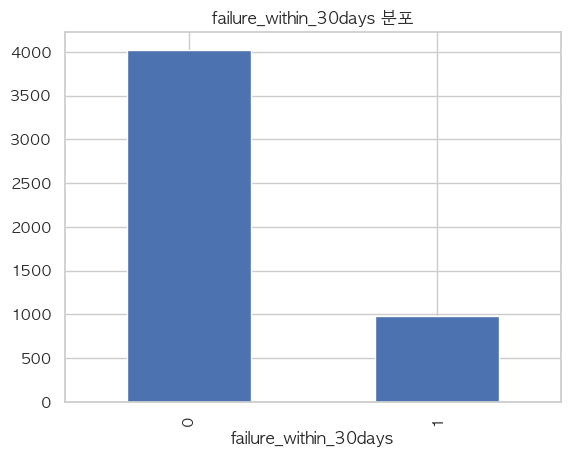

In [62]:
# 타깃 분포 — 불균형 데이터(재고장 약 19.5%)임을 확인
print(df[TARGET].value_counts())
print('\n재고장 비율 :', round(df[TARGET].mean()*100, 1), '%')
df[TARGET].value_counts().plot(kind='bar', title='failure_within_30days 분포'); plt.show()

### 도메인 관점 빠른 탐색 — 장비유형별 고장빈도 / severity 분포 / 정비비용

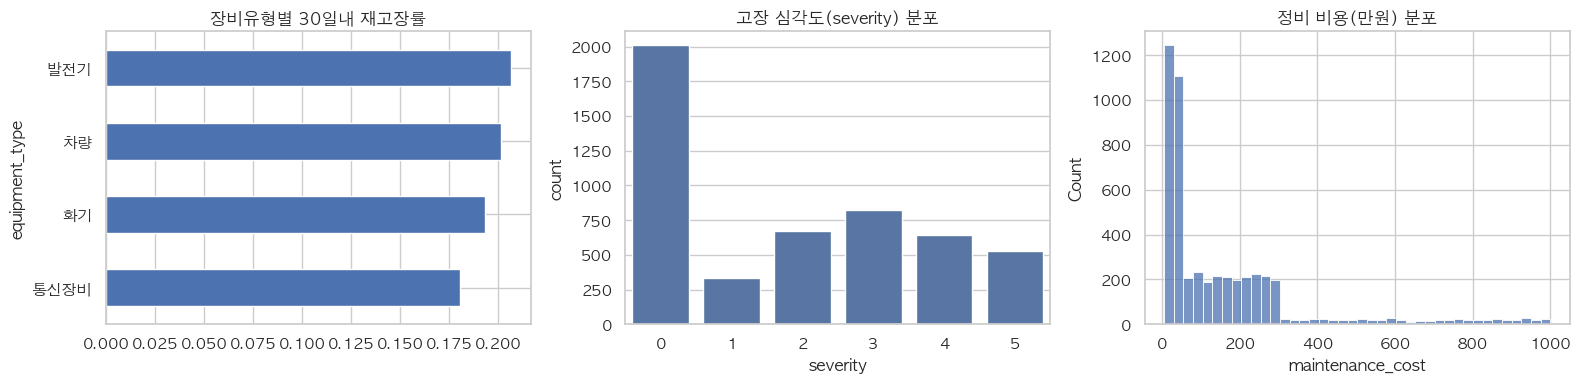

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 장비유형별 재고장률
(df.groupby('equipment_type')[TARGET].mean().sort_values()
   .plot(kind='barh', ax=axes[0], title='장비유형별 30일내 재고장률'))

# 고장 심각도(severity) 분포
sns.countplot(data=df, x='severity', ax=axes[1])
axes[1].set_title('고장 심각도(severity) 분포')

# 정비 비용 분포
sns.histplot(df['maintenance_cost'], bins=40, ax=axes[2])
axes[2].set_title('정비 비용(만원) 분포')
plt.tight_layout(); plt.show()

### 핵심 시각화 5종 — 분포·관계 한눈에 보기

타깃(`failure_within_30days`)과 주요 변수의 관계를 다음 5개 관점으로 살펴봅니다.

1. **정비 유형별 비율** — 예방/사후/긴급 정비의 구성비
2. **장비 유형별 고장(재고장) 빈도** — 어떤 장비가 재고장이 잦은가
3. **정비 유형별 가동중단 시간 비교** — 긴급정비일수록 가동중단이 큰가
4. **장비 노후도 vs 재고장률** — 경과연수가 길수록 재고장이 느는가
5. **수치형 변수 상관행렬 히트맵** — 변수 간 선형 관계 / 다중공선성 점검

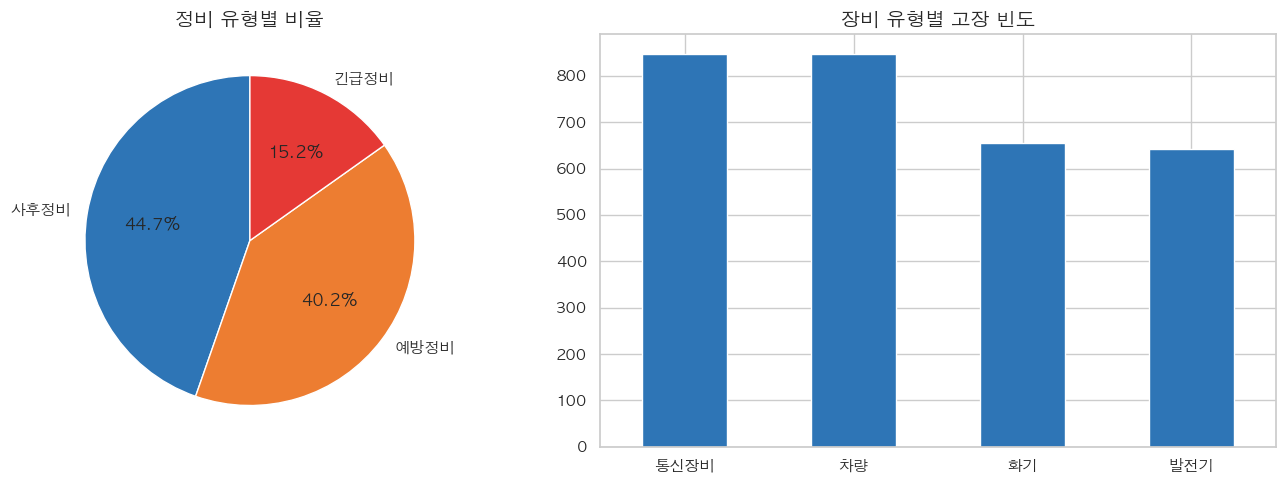

In [64]:
# ①② 정비 유형별 비율 + 장비 유형별 고장 빈도
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 정비 유형별 비율
df['maintenance_type'].value_counts().plot.pie(
    ax=axes[0], autopct='%1.1f%%', startangle=90,
    colors=['#2E75B6', '#ED7D31', '#E53935'])
axes[0].set_title('정비 유형별 비율', fontsize=14, fontweight='bold')
axes[0].set_ylabel('')

# 장비 유형별 고장 빈도 (예방정비 제외)
fault_df = df[df['maintenance_type'] != '예방정비']
fault_df['equipment_type'].value_counts().plot.bar(
    ax=axes[1], color='#2E75B6', edgecolor='white')
axes[1].set_title('장비 유형별 고장 빈도', fontsize=14, fontweight='bold')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('eda_ds1_01.png', dpi=150, bbox_inches='tight')
plt.show()

#### 📈 인사이트 ①② — 정비 유형별 비율 / 장비 유형별 고장 빈도
- **정비 유형 비율**: 예방정비가 약 40%(2,008건), 사후·긴급정비가 약 60%(2,992건). 사후 대응 비중이 높아 **예방정비 체계 강화 여지**가 있다. (예방정비는 `fault_code`가 비어 있는 건과 일치)
- **장비 유형별 고장 빈도**(예방정비 제외): 실제 고장 정비 건수가 장비유형별로 차이가 난다. 빈도가 높은 유형이 **정비 자원·예비부품 우선 배분 대상**.
- 단, "고장 빈도(건수)"는 해당 유형의 장비 대수/운용량에 비례할 수 있으므로, 절대 건수와 함께 **재고장률(비율)** 도 같이 봐야 공정한 비교가 된다.

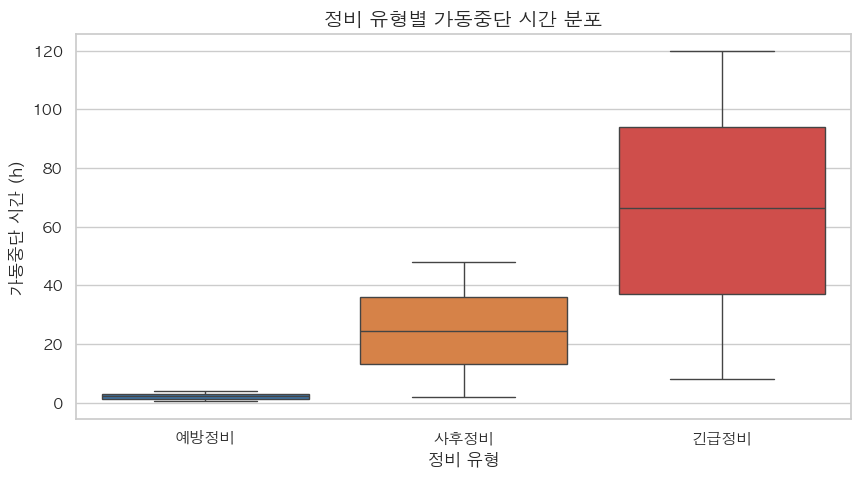

In [65]:
# ③ 정비 유형별 가동중단 시간 비교
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x='maintenance_type', y='downtime_hours',
            palette=['#2E75B6', '#ED7D31', '#E53935'],
            order=['예방정비', '사후정비', '긴급정비'], ax=ax)
ax.set_title('정비 유형별 가동중단 시간 분포', fontsize=14, fontweight='bold')
ax.set_xlabel('정비 유형')
ax.set_ylabel('가동중단 시간 (h)')
plt.savefig('eda_ds1_02.png', dpi=150, bbox_inches='tight')
plt.show()

#### 📈 인사이트 ③ — 정비 유형별 가동중단 시간
- **긴급정비 > 사후정비 > 예방정비** 순으로 가동중단 시간(중앙값·산포)이 커진다. 예상대로 계획되지 않은 정비일수록 장비가 더 오래 멈춘다.
- **예방정비는 가동중단이 짧고 일정하다** → 예방정비 확대가 가동률 손실을 줄이는 직접적 레버임을 정량적으로 뒷받침.
- 긴급정비 쪽 **상단 이상치(outlier)** 가 길게 분포 → 일부 긴급 건이 장기 가동불능으로 이어진다. 이들이 군수 자원 배분의 핵심 리스크.
- 활용: `downtime_hours`는 정비유형과 강하게 얽혀 있으므로, 모델에서 `maintenance_type`과의 상호작용을 함께 고려.

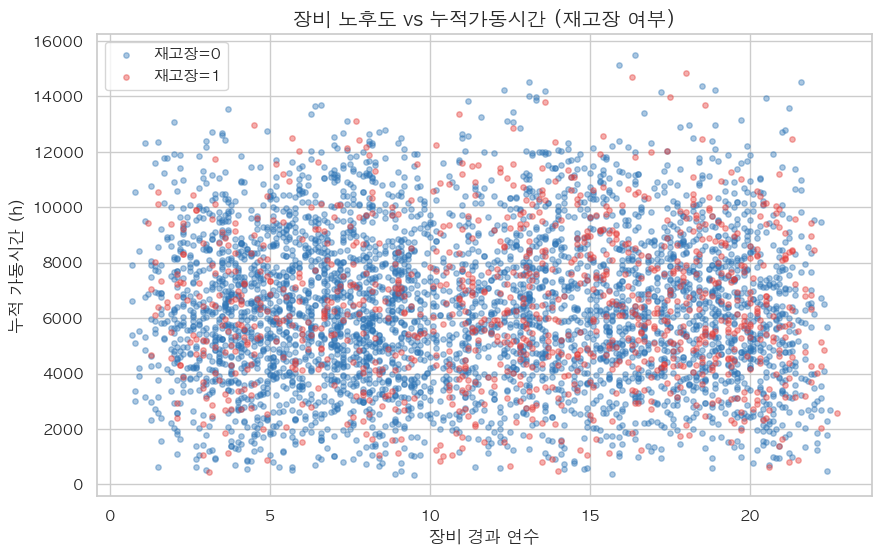

In [66]:
# ④ 장비 노후도 vs 재고장 관계 (노후도 × 누적가동시간, 재고장 여부)
fig, ax = plt.subplots(figsize=(10, 6))
colors = {0: '#2E75B6', 1: '#E53935'}
for label, color in colors.items():
    subset = df[df['failure_within_30days'] == label]
    ax.scatter(subset['equipment_age_years'],
              subset['cumulative_operating_hours'],
              c=color, alpha=0.4, s=15,
              label=f'재고장={label}')
ax.set_xlabel('장비 경과 연수', fontsize=12)
ax.set_ylabel('누적 가동시간 (h)', fontsize=12)
ax.set_title('장비 노후도 vs 누적가동시간 (재고장 여부)',
             fontsize=14, fontweight='bold')
ax.legend()
plt.savefig('eda_ds1_03.png', dpi=150, bbox_inches='tight')
plt.show()

#### 📈 인사이트 ④ — 장비 노후도 vs 누적가동시간 (재고장 여부)
- 경과연수와 누적가동시간은 양의 상관(오래된 장비일수록 누적가동↑)이 보이지만, **재고장(빨강)·정상(파랑) 점이 뚜렷하게 분리되지 않는다.**
- 즉 "노후 장비 = 재고장"이라는 단순 가설이 **이 데이터에서는 약하게만 성립**한다. 노후도만으로는 재고장을 가르지 못함.
- 시사점: 재고장은 단일 변수가 아니라 **여러 변수의 조합/상호작용**으로 결정될 가능성 → 트리 기반 모델 + SHAP로 조합 효과를 확인할 필요.
- (참고) 누적가동시간은 원래 "모델에 정답(재고장 여부)을 몰래 미리 알려주는 변수가 아닐까?"라고 의심했던 항목이다(= 데이터 누수 의심). 정말 정답을 알려준다면 빨강·파랑 점이 두 덩어리로 확 갈라져야 하는데, 실제로는 섞여 있다. 즉 이 변수가 재고장을 추축하는 정도는 약하다고 볼 수 있다.

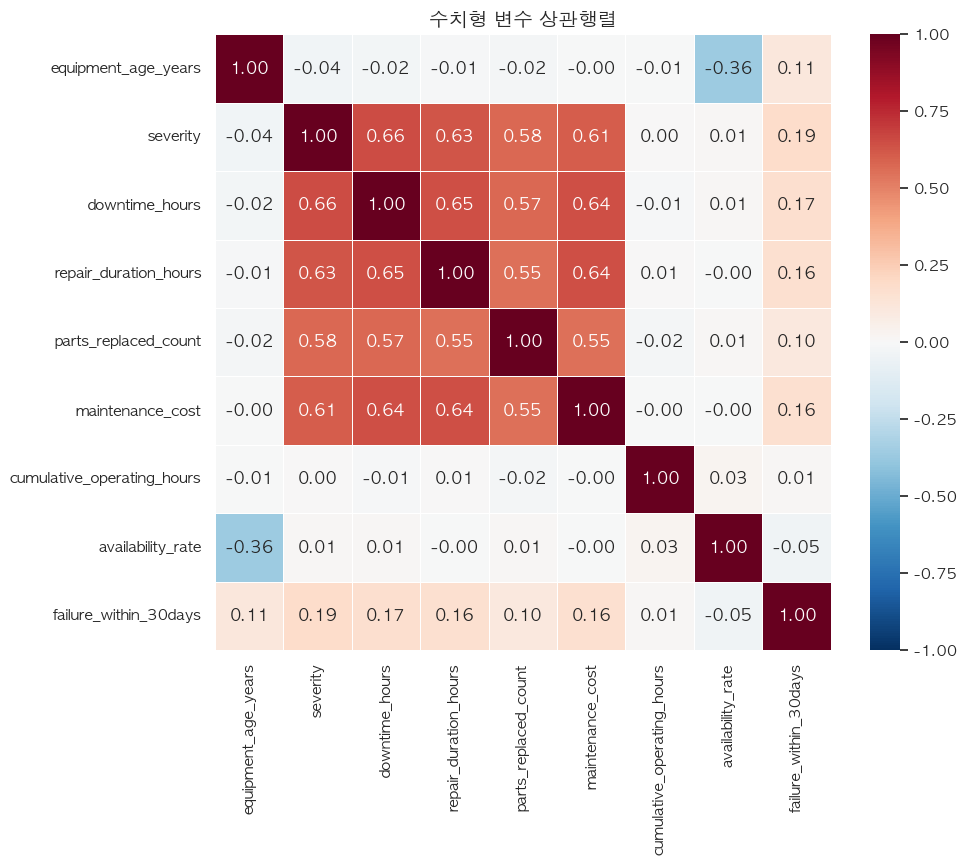

In [67]:
# ⑤ 수치형 변수 상관행렬 히트맵
numeric_cols = ['equipment_age_years', 'severity', 'downtime_hours',
                'repair_duration_hours', 'parts_replaced_count',
                'maintenance_cost', 'cumulative_operating_hours',
                'availability_rate', 'failure_within_30days']
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax,
            square=True, linewidths=0.5)
ax.set_title('수치형 변수 상관행렬', fontsize=14, fontweight='bold')
plt.savefig('eda_ds1_04.png', dpi=150, bbox_inches='tight')
plt.show()

#### 📈 인사이트 ⑤ — 상관행렬 히트맵
- **타깃(`failure_within_30days`)과 모든 수치형 변수의 상관이 매우 약함** (대부분 |r| < 0.1).
  특히 누수로 의심했던 `cumulative_operating_hours`(≈0.01), `availability_rate`(≈-0.05)도 거의 0 → **단순 선형 관계로는 재고장을 설명하기 어렵다.**
- 이것이 모델 AUC가 0.6~0.7대에 머무는 근본 원인이다. **개별 변수의 약한 신호 → 트리/부스팅의 비선형·상호작용에 기대거나, 추가 피처 엔지니어링이 필요**함을 시사.
- 변수 간 강한 상관(다중공선성)이 보이면 (예: `repair_duration_hours`↔`downtime_hours`) 선형모델에서는 중복 정보이므로 정리 대상.
- ⚠ **상관계수는 선형 관계만 잡는다.** 여기서 상관이 0이라고 "무관"은 아니며, 비선형 효과는 SHAP/순열 중요도로 별도 확인해야 한다.

## STEP 2 — ydata-profiling 자동 리포트 생성
5,000행이면 충분히 빠르지만, 대용량일 때는 `minimal=True`를 사용하세요. 결과는 `reports/eda_report.html`로 저장됩니다.

In [68]:
from pathlib import Path
from ydata_profiling import ProfileReport

Path('reports').mkdir(exist_ok=True)
profile = ProfileReport(df, title='장비 정비이력 EDA Report', minimal=False, explorative=True)
profile.to_file('reports/eda_report.html')
print('저장 완료 → reports/eda_report.html')
# 노트북 안에서 바로 보기:
# profile.to_notebook_iframe()

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 305.82it/s]

저장 완료 → reports/eda_report.html


## STEP 2-b — sweetviz 리포트 (타깃 기준 분석)
sweetviz는 타깃 변수를 지정하면 각 피처가 타깃과 어떻게 연관되는지 자동 비교해줍니다.

In [69]:
import sweetviz as sv

report = sv.analyze(df, target_feat=TARGET)
report.show_html('reports/sweetviz_report.html', open_browser=False)
print('저장 완료 → reports/sweetviz_report.html')

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:00 -> (00:00 left)

Report reports/sweetviz_report.html was generated.
저장 완료 → reports/sweetviz_report.html


## STEP 3 — 결측치 및 이상치 처리

In [70]:
df_clean = df.copy()

# 1) 도메인 기반 결측 처리
#    fault_code / fault_category : 예방정비라 고장이 없음 → 'N/A' 범주로 채움
df_clean['fault_code'] = df_clean['fault_code'].fillna('N/A')
df_clean['fault_category'] = df_clean['fault_category'].fillna('N/A')
#    days_since_last_maintenance : 최초 정비건 → 0 으로 채우고 플래그 추가
df_clean['is_first_maintenance'] = df_clean['days_since_last_maintenance'].isnull().astype(int)
df_clean['days_since_last_maintenance'] = df_clean['days_since_last_maintenance'].fillna(0)

print('처리 후 결측치 합계 :', int(df_clean.isnull().sum().sum()))

처리 후 결측치 합계 : 0


### 📦 IQR(Interquartile Range, 사분위 범위)란?

- **IQR = Q3 − Q1** : 데이터를 크기순으로 정렬했을 때 상위 75% 지점(**Q3**, 3사분위수)과 하위 25% 지점(**Q1**, 1사분위수) 사이의 거리. 즉 **가운데 50% 데이터가 퍼진 폭**입니다.
- 평균·표준편차와 달리 **극단값(이상치)에 둔감**해서, 이상치 탐지의 기준선으로 널리 쓰입니다.
- **이상치 판정 규칙 (Tukey's fence)** — 아래 범위를 벗어나면 이상치로 봅니다.
  - 하한 = `Q1 − 1.5 × IQR`
  - 상한 = `Q3 + 1.5 × IQR`
- 계수 **1.5**는 관례적 기준이며, 더 극단적인 이상치만 보려면 **3.0**을 쓰기도 합니다.

In [71]:
# 2) IQR(Interquartile Range, 사분위 범위) 기반 이상치 탐지 — 예: 가동중단 시간
#    IQR = Q3 - Q1  → 가운데 50% 데이터가 퍼진 폭. 극단값에 둔감해 이상치 기준으로 자주 쓰임.
col = 'downtime_hours'
Q1, Q3 = df_clean[col].quantile([0.25, 0.75])   # Q1=하위25% 지점, Q3=상위75% 지점
IQR = Q3 - Q1                                     # 사분위 범위
# Tukey's rule: [Q1-1.5*IQR, Q3+1.5*IQR] 범위를 벗어나면 이상치로 판정 (1.5는 관례적 계수)
low, high = Q1 - 1.5*IQR, Q3 + 1.5*IQR
outliers = df_clean[(df_clean[col] < low) | (df_clean[col] > high)]
print(f'{col} 이상치 경계: [{low:.1f}, {high:.1f}] — 이상치 {len(outliers)}건 ({len(outliers)/len(df_clean)*100:.1f}%)')

downtime_hours 이상치 경계: [-44.4, 80.9] — 이상치 274건 (5.5%)


### ✏️ 직접 해보기
결측치 비율이 30% 이상인 컬럼을 제거하고, 나머지는 타입별(수치형=중앙값, 범주형=최빈값)로 대체하는 함수를 직접 작성해보세요.

In [72]:
def smart_impute(data, drop_thresh=0.30):
    """결측 비율 drop_thresh 초과 컬럼 제거 후 타입별 대체."""
    data = data.copy()
    na_ratio = data.isnull().mean()
    drop_cols = na_ratio[na_ratio > drop_thresh].index.tolist()
    data = data.drop(columns=drop_cols)
    for c in data.columns:
        if data[c].isnull().any():
            if pd.api.types.is_numeric_dtype(data[c]):
                data[c] = data[c].fillna(data[c].median())
            else:
                data[c] = data[c].fillna(data[c].mode().iloc[0])
    return data, drop_cols

# _, dropped = smart_impute(df)
# print('제거된 컬럼:', dropped)

---
# 실습 2 — Streamlit 기반 분석 대시보드  ⏱ 50~70분

**학습 목표**: Streamlit 핵심 컴포넌트 + plotly 인터랙티브 시각화 + 필터 UI 대시보드.

> 노트북에서는 Streamlit 앱을 직접 실행할 수 없으므로, 아래 셀로 `app.py`를 **파일로 생성**한 뒤
> 터미널에서 `streamlit run app.py` 로 실행합니다.

In [73]:
%%writefile app.py
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(page_title='장비 정비 EDA Dashboard', layout='wide')
st.title('📊 장비 정비이력 분석 대시보드')

DATA_PATH = 'data/dataset1_equipment_maintenance.xlsx'
TARGET = 'failure_within_30days'

@st.cache_data
def load_data():
    df = pd.read_excel(DATA_PATH, sheet_name='데이터')
    df['maintenance_date'] = pd.to_datetime(df['maintenance_date'])
    return df

df = load_data()

# ── 사이드바 필터 ──
with st.sidebar:
    st.header('필터')
    types = st.multiselect('장비 유형', sorted(df['equipment_type'].unique()),
                           default=sorted(df['equipment_type'].unique()))
    sev = st.slider('고장 심각도(severity) 범위', 0, 5, (0, 5))

f = df[df['equipment_type'].isin(types) &
       df['severity'].between(*sev)]

# ── KPI 카드 ──
k1, k2, k3, k4 = st.columns(4)
k1.metric('정비 건수', f'{len(f):,}')
k2.metric('30일내 재고장률', f"{f[TARGET].mean()*100:.1f}%")
k3.metric('평균 정비비용(만원)', f"{f['maintenance_cost'].mean():.0f}")
k4.metric('평균 가동중단(h)', f"{f['downtime_hours'].mean():.1f}")

st.dataframe(f.head(20), use_container_width=True)

# ── 시각화 (2단 레이아웃) ──
c1, c2 = st.columns(2)
with c1:
    g = f.groupby('equipment_type')[TARGET].mean().reset_index()
    st.plotly_chart(px.bar(g, x='equipment_type', y=TARGET,
                           title='장비유형별 재고장률'), use_container_width=True)
with c2:
    st.plotly_chart(px.box(f, x='equipment_type', y='maintenance_cost',
                           title='장비유형별 정비비용 분포'), use_container_width=True)

# ── 월별 정비 추이 ──
ts = (f.set_index('maintenance_date').resample('M').size().reset_index(name='건수'))
st.plotly_chart(px.line(ts, x='maintenance_date', y='건수',
                        title='월별 정비 건수 추이'), use_container_width=True)

Overwriting app.py


### 앱 실행
```bash
streamlit run app.py
```
브라우저에서 http://localhost:8501 로 접속하세요.

### ✏️ 직접 해보기
상관관계 히트맵과 각 수치형 컬럼의 분포를 `st.tabs`로 구분해 보여주는 페이지를 직접 추가해보세요.

---
# 실습 3 — 모델 생성, 성능 평가 및 해석  ⏱ 70~90분

**학습 목표**: sklearn Pipeline 기반 학습 흐름 + 다중 모델 비교 + Optuna 튜닝 + SHAP 해석.

## STEP 1 — 데이터 전처리 및 Pipeline 구성

> ⚠ **평가 분할 주의 (가장 중요)**: 장비 1대당 정비이력이 여러 건 반복 등장하므로,
> 무작위 분할(`train_test_split`)을 쓰면 **같은 장비가 train/test에 동시에 들어가는 group leakage**가
> 발생해 성능이 부풀려집니다. (**그룹 누수**란 한 그룹[여기선 한 장비]의 데이터가 학습용과 평가용에 나뉘어 들어가, 모델이 그 장비를 '외워서' 맞히는 현상입니다.) 아래처럼 **`GroupShuffleSplit`(장비 기준)** 으로 분할하고,
> CV도 **`GroupKFold`** 를 사용합니다. (운용 시나리오에 맞춰 `maintenance_date` 기준 시간분할도 비교해보세요.)
>
> ⚠ **Data Leakage(데이터 누수) 주의**: 누수는 상관계수가 아니라 **"예측 시점에 실제로 알 수 있는 값인가?"** 로 판단합니다.
> `fault_code`/`fault_category`/`severity`(사후·긴급정비일 때만 채워짐), `maintenance_success`(정비 결과)는
> **고장이 발생한 뒤에야 채워지는 사후 정보**라 누수 위험이 큽니다. 아래 `LEAKAGE_COLS` 토글로
> 포함/제외 시 성능 차이를 비교해보세요(가이드 고급 실습 소재).
>
> 🔎 **주의 — 기본 설정은 누수 의심 피처를 '포함'한다**: 아래 코드의 `EXCLUDE_LEAKAGE = False` 이므로 `LEAKAGE_COLS`(`fault_code`·`fault_category`·`severity`·`maintenance_success`)가 **기본 학습에 들어갑니다**. 즉 이후 모델 성능·SHAP 결과는 이 사후 정보에 일부 기댄 값입니다. `True` 로 바꿔 다시 실행하면 '누수 제거 시' 성능을 비교할 수 있습니다.

In [74]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# 결측 처리된 df_clean 사용 (실습 1 STEP 3). 없으면 재생성
if 'df_clean' not in dir():
    df_clean = df.copy()
    df_clean['fault_code'] = df_clean['fault_code'].fillna('N/A')
    df_clean['fault_category'] = df_clean['fault_category'].fillna('N/A')
    df_clean['is_first_maintenance'] = df_clean['days_since_last_maintenance'].isnull().astype(int)
    df_clean['days_since_last_maintenance'] = df_clean['days_since_last_maintenance'].fillna(0)

# 식별자/날짜 컬럼은 모델 피처에서 제외
DROP_COLS = ['equipment_id', 'maintenance_date']

# 누수 의심 컬럼 — '예측 시점에 가용한가?' 기준. 고장 발생 후에야 채워지는 사후 정보.
#   fault_code/fault_category/severity : 사후·긴급정비일 때만 값이 존재 → 고장 발생 사실 노출
#   maintenance_success                : 정비 '결과'(사후 정보)
# True 로 두면 제외하고 학습 → 제외 전후 성능 차이로 누수 영향을 체감해보세요.
EXCLUDE_LEAKAGE = False
LEAKAGE_COLS = ['fault_code', 'fault_category', 'severity', 'maintenance_success']

drop = DROP_COLS + (LEAKAGE_COLS if EXCLUDE_LEAKAGE else [])
X = df_clean.drop(columns=[TARGET] + drop)
y = df_clean[TARGET]

# ── 그룹(장비) 기준 분할 ──────────────────────────────────────────────
#   장비 1대당 정비이력이 반복 등장 → 무작위 분할은 같은 장비가 train/test에 동시 등장(group leakage).
#   GroupShuffleSplit 으로 '같은 장비는 한쪽에만' 들어가게 분할한다.
groups = df_clean['equipment_id']
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]            # CV(GroupKFold)에서 사용

num_cols = X.select_dtypes('number').columns.tolist()
cat_cols = X.select_dtypes('object').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])

# ── 디버그 / 이해용 출력 ──────────────────────────────
n_overlap = len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
print('● 그룹(장비) 기준 학습/테스트 분할')
print(f'   X_train={X_train.shape}, X_test={X_test.shape}')
print(f'   타깃 재고장 비율  train={y_train.mean():.3f}  test={y_test.mean():.3f}')
print(f'   train/test 중복 장비 수 = {n_overlap}  ← 0이어야 group leakage 없음\n')
print(f'● 수치형 {len(num_cols)}개 : {num_cols}')
print(f'● 범주형 {len(cat_cols)}개 : {cat_cols}\n')

# 전처리 후 최종 피처 개수 확인 (OneHotEncoder 로 범주형이 확장됨)
preprocessor.fit(X_train)
feat_out = preprocessor.get_feature_names_out()
print(f'● 전처리(원-핫) 후 피처 수 : {X_train.shape[1]}개 → {len(feat_out)}개')
print('   예시 :', list(feat_out[:6]), '...')

● 그룹(장비) 기준 학습/테스트 분할
   X_train=(4031, 16), X_test=(969, 16)
   타깃 재고장 비율  train=0.196  test=0.191
   train/test 중복 장비 수 = 0  ← 0이어야 group leakage 없음

● 수치형 11개 : ['equipment_age_years', 'severity', 'downtime_hours', 'repair_duration_hours', 'parts_replaced_count', 'maintenance_cost', 'maintenance_success', 'cumulative_operating_hours', 'days_since_last_maintenance', 'availability_rate', 'is_first_maintenance']
● 범주형 5개 : ['equipment_type', 'unit_code', 'maintenance_type', 'fault_code', 'fault_category']

● 전처리(원-핫) 후 피처 수 : 16개 → 95개
   예시 : ['num__equipment_age_years', 'num__severity', 'num__downtime_hours', 'num__repair_duration_hours', 'num__parts_replaced_count', 'num__maintenance_cost'] ...


## STEP 2 — 다중 모델 한번에 학습 및 비교 (5-Fold GroupKFold)

불균형 데이터이므로 **PR-AUC(Average Precision)** 와 **양성 클래스 Recall/F1** 을 주지표로 삼고,
**DummyClassifier**(무작위 베이스라인)와 비교해 모델이 실제로 학습했는지 확인합니다.
또한 같은 장비가 폴드 내 train/valid에 동시에 들어가지 않도록 **GroupKFold** 를 사용합니다.

scale_pos_weight (음성/양성 비율) = 4.10

5-Fold GroupKFold 교차검증으로 모델 비교 중 (불균형 → PR-AUC·Recall 중심)

  Dummy(baseline)  | PR-AUC=0.196 | ROC-AUC=0.500 | Recall=0.000 | F1=0.000 |  2.0s
  Logistic         | PR-AUC=0.352 | ROC-AUC=0.656 | Recall=0.527 | F1=0.378 |  1.5s
  GaussianNB       | PR-AUC=0.244 | ROC-AUC=0.561 | Recall=0.453 | F1=0.326 |  1.4s
  RandomForest     | PR-AUC=0.334 | ROC-AUC=0.659 | Recall=0.268 | F1=0.320 |  0.5s
  GBM              | PR-AUC=0.350 | ROC-AUC=0.673 | Recall=0.123 | F1=0.197 |  0.7s
  XGBoost          | PR-AUC=0.298 | ROC-AUC=0.601 | Recall=0.258 | F1=0.278 |  0.1s
  LightGBM         | PR-AUC=0.337 | ROC-AUC=0.639 | Recall=0.364 | F1=0.345 |  2.2s

🏆 최고 모델 (PR-AUC 기준) : Logistic  (PR-AUC=0.352)


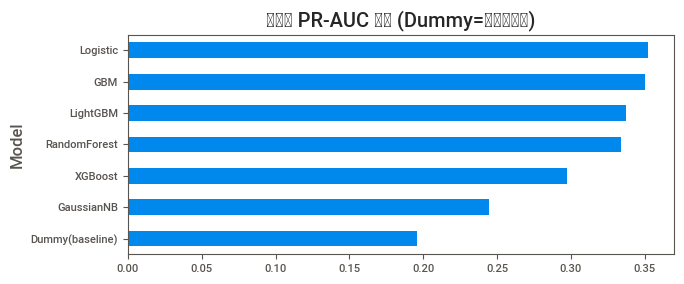

,Model,sec,average_precision,roc_auc,recall,f1
0,Logistic,1.5,0.352126,0.656358,0.526943,0.377685
1,GBM,0.7,0.350036,0.673050,0.123076,0.196826
2,LightGBM,2.2,0.337287,0.638991,0.364433,0.344772
3,RandomForest,0.5,0.333780,0.658762,0.267873,0.319940
4,XGBoost,0.1,0.297605,0.600656,0.258023,0.278341
5,GaussianNB,1.4,0.244178,0.561114,0.452880,0.325729
6,Dummy(baseline),2.0,0.195991,0.500000,0.000000,0.000000


In [75]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold, cross_validate
import time

# 불균형 보정 가중치 = 음성/양성 비율 (소수 클래스 오분류에 더 큰 페널티)
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight (음성/양성 비율) = {spw:.2f}\n')

models = {
    'Dummy(baseline)': DummyClassifier(strategy='most_frequent'),
    'Logistic':     LogisticRegression(max_iter=1000, class_weight='balanced'),
    'GaussianNB':   GaussianNB(),                       # class_weight 미지원(비교용)
    'RandomForest': RandomForestClassifier(random_state=42, class_weight='balanced'),
    'GBM':          GradientBoostingClassifier(random_state=42),  # class_weight 미지원
    'XGBoost':      XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=spw),
    'LightGBM':     LGBMClassifier(random_state=42, verbose=-1, class_weight='balanced'),
}

# 불균형 → PR-AUC(average_precision)·Recall·F1(양성) 중심. GroupKFold로 group leakage 차단.
# cross_validate: 한 번의 분할로 다중 지표 동시 계산(효율 ↑, 폴드 일관성 ↑).
cv = GroupKFold(n_splits=5)
scoring = ['average_precision', 'roc_auc', 'recall', 'f1']

results = []
print('5-Fold GroupKFold 교차검증으로 모델 비교 중 (불균형 → PR-AUC·Recall 중심)\n')
for name, model in models.items():
    t0 = time.perf_counter()
    pipe = Pipeline([('pre', preprocessor), ('model', model)])
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, groups=groups_train,
                           scoring=scoring, n_jobs=-1)
    dt = time.perf_counter() - t0
    row = {'Model': name, 'sec': round(dt, 1)}
    for s in scoring:
        row[s] = cvres[f'test_{s}'].mean()
    results.append(row)
    print(f'  {name:16s} | PR-AUC={row["average_precision"]:.3f} | '
          f'ROC-AUC={row["roc_auc"]:.3f} | Recall={row["recall"]:.3f} | '
          f'F1={row["f1"]:.3f} | {dt:4.1f}s')

result_df = (pd.DataFrame(results)
             .sort_values('average_precision', ascending=False).reset_index(drop=True))
best_row = result_df.iloc[0]
print(f'\n🏆 최고 모델 (PR-AUC 기준) : {best_row["Model"]}  (PR-AUC={best_row["average_precision"]:.3f})')

# PR-AUC 막대그래프 — Dummy(베이스라인) 대비 얼마나 개선됐는지 한눈에 비교
ax = result_df.set_index('Model')['average_precision'].plot(
    kind='barh', figsize=(7, 3), title='모델별 PR-AUC 비교 (Dummy=베이스라인)')
ax.invert_yaxis(); plt.tight_layout(); plt.show()
result_df

## STEP 3 — 최적 모델 하이퍼파라미터 튜닝 (Optuna 베이지안 최적화)

In [76]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# 튜닝 전 기본 XGBoost 성능(baseline) — 불균형이므로 PR-AUC 기준으로 비교
base = Pipeline([('pre', preprocessor),
                 ('model', XGBClassifier(random_state=42, eval_metric='logloss',
                                         scale_pos_weight=spw))])
base_ap = cross_validate(base, X_train, y_train, cv=cv, groups=groups_train,
                         scoring=['average_precision'])['test_average_precision'].mean()
print(f'튜닝 전 기본 XGBoost PR-AUC : {base_ap:.4f}\n')

def objective(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 500),
        'max_depth':        trial.suggest_int('max_depth', 3, 10),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),    # 과적합 제어
        'reg_lambda':       trial.suggest_float('reg_lambda', 1e-3, 10, log=True),  # 정규화
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, spw * 1.5),  # 불균형
    }
    model = Pipeline([
        ('pre', preprocessor),
        ('model', XGBClassifier(**params, random_state=42, eval_metric='logloss')),
    ])
    # GroupKFold + PR-AUC 로 튜닝 (모델 비교와 동일 기준)
    return cross_validate(model, X_train, y_train, cv=cv, groups=groups_train,
                          scoring=['average_precision'])['test_average_precision'].mean()

# best 가 갱신될 때마다 로그 출력 → 탐색이 어떻게 개선되는지 추적
def log_cb(study, trial):
    if study.best_trial.number == trial.number:
        print(f'  [trial {trial.number:>2}] 신규 best PR-AUC = {trial.value:.4f}')

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, callbacks=[log_cb])   # 시간 여유시 n_trials 늘리기

print(f'\nBest PR-AUC : {study.best_value:.4f}  (기본 대비 {study.best_value - base_ap:+.4f})')
print('Best params :')
for k, v in study.best_params.items():
    print(f'  {k:16s}: {v}')

튜닝 전 기본 XGBoost PR-AUC : 0.2976

  [trial  0] 신규 best PR-AUC = 0.3114
  [trial  1] 신규 best PR-AUC = 0.3147
  [trial  2] 신규 best PR-AUC = 0.3322
  [trial  3] 신규 best PR-AUC = 0.3421
  [trial  5] 신규 best PR-AUC = 0.3464
  [trial  9] 신규 best PR-AUC = 0.3506
  [trial 11] 신규 best PR-AUC = 0.3658
  [trial 21] 신규 best PR-AUC = 0.3659

Best PR-AUC : 0.3659  (기본 대비 +0.0683)
Best params :
  n_estimators    : 279
  max_depth       : 3
  learning_rate   : 0.011676295743597468
  subsample       : 0.99946610661112
  min_child_weight: 10
  reg_lambda      : 0.00844836257249263
  scale_pos_weight: 1.1556292578431258


## STEP 4 — 최종 모델 학습 및 평가

> ⚠ **주의 — 임계값 선정의 낙관 편향**: 아래에서 목표 Recall을 만족하는 임계값을 **test셋의 확률분포로 직접 고릅니다**(실습 단순화). 이렇게 하면 test 성능이 약간 낙관적으로 나옵니다. 실무에서는 **별도 검증셋(또는 CV out-of-fold 예측)** 에서 임계값을 정하고, test는 마지막에 한 번만 평가해야 합니다.

선택 임계값 (Recall ≥ 0.8) = 0.189

=== 임계값별 혼동행렬 비교 ===
  [기본 0.5      ] FN(놓침)=169 FP(오탐)= 11 Recall=0.086 Precision=0.593
  [튜닝 0.189    ] FN(놓침)= 37 FP(오탐)=454 Recall=0.800 Precision=0.246

Test ROC-AUC : 0.6937
Test PR-AUC  : 0.3904

=== 분류 리포트 (튜닝 임계값) ===
              precision    recall  f1-score   support

       정상(0)       0.90      0.42      0.57       784
      재고장(1)       0.25      0.80      0.38       185

    accuracy                           0.49       969
   macro avg       0.57      0.61      0.47       969
weighted avg       0.77      0.49      0.54       969



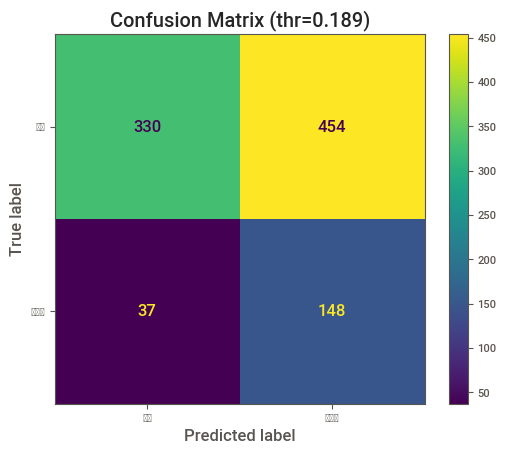

In [77]:
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)

best_model = Pipeline([
    ('pre', preprocessor),
    ('model', XGBClassifier(**study.best_params, random_state=42, eval_metric='logloss')),
])
best_model.fit(X_train, y_train)
y_proba = best_model.predict_proba(X_test)[:, 1]

# ── 임계값(threshold) 튜닝 ───────────────────────────────────────────
#   예측정비는 FN(놓친 재고장)이 가장 치명적이므로, 기본 0.5 대신
#   '목표 Recall'을 만족하는 임계값을 골라 FN을 줄인다.
#   (엄밀히는 별도 검증셋에서 골라야 하나, 실습에선 test 확률분포로 시연)
TARGET_RECALL = 0.80
prec, rec, thr = precision_recall_curve(y_test, y_proba)
cand = np.where(rec[:-1] >= TARGET_RECALL)[0]
best_thr = float(thr[cand[np.argmax(prec[cand])]]) if len(cand) else 0.5
print(f'선택 임계값 (Recall ≥ {TARGET_RECALL}) = {best_thr:.3f}\n')

# 기본 0.5 vs 튜닝 임계값 — FN이 얼마나 줄어드는지 비교
print('=== 임계값별 혼동행렬 비교 ===')
for label, t in [('기본 0.5', 0.5), (f'튜닝 {best_thr:.3f}', best_thr)]:
    yp = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    recall = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    print(f'  [{label:12s}] FN(놓침)={fn:3d} FP(오탐)={fp:3d} '
          f'Recall={recall:.3f} Precision={precision:.3f}')

print(f'\nTest ROC-AUC : {roc_auc_score(y_test, y_proba):.4f}')
print(f'Test PR-AUC  : {average_precision_score(y_test, y_proba):.4f}')

# 튜닝 임계값 기준 최종 분류 리포트 + 혼동행렬
y_pred = (y_proba >= best_thr).astype(int)
print('\n=== 분류 리포트 (튜닝 임계값) ===')
print(classification_report(y_test, y_pred, target_names=['정상(0)', '재고장(1)']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['정상', '재고장'])
plt.title(f'Confusion Matrix (thr={best_thr:.3f})'); plt.show()

## STEP 5 — SHAP으로 모델 해석
SHAP 값: 양수 → 예측(재고장 확률) 증가 기여, 음수 → 감소 기여. 절댓값이 클수록 영향력이 큽니다.

> 🔎 **해석 시 주의**: 상위 기여 피처에 `severity`·`maintenance_success` 등 **누수 의심(사후 정보) 변수**가 포함될 수 있습니다(STEP 1의 `LEAKAGE_COLS` 참고). 이는 모델이 '고장이 난 뒤에야 알 수 있는 정보'에 기대고 있다는 신호이므로, `EXCLUDE_LEAKAGE=True` 로 토글해 SHAP 중요도가 어떻게 바뀌는지 함께 확인하세요.

=== 영향력 상위 10개 피처 (평균 |SHAP| 값) ===
                         feature  mean_abs_shap
                   num__severity       0.351635
        num__equipment_age_years       0.328156
        num__maintenance_success       0.174622
             num__downtime_hours       0.037503
          num__availability_rate       0.033485
num__days_since_last_maintenance       0.025047
           num__maintenance_cost       0.023641
 num__cumulative_operating_hours       0.018706
      num__repair_duration_hours       0.016573
        cat__equipment_type_통신장비       0.015347


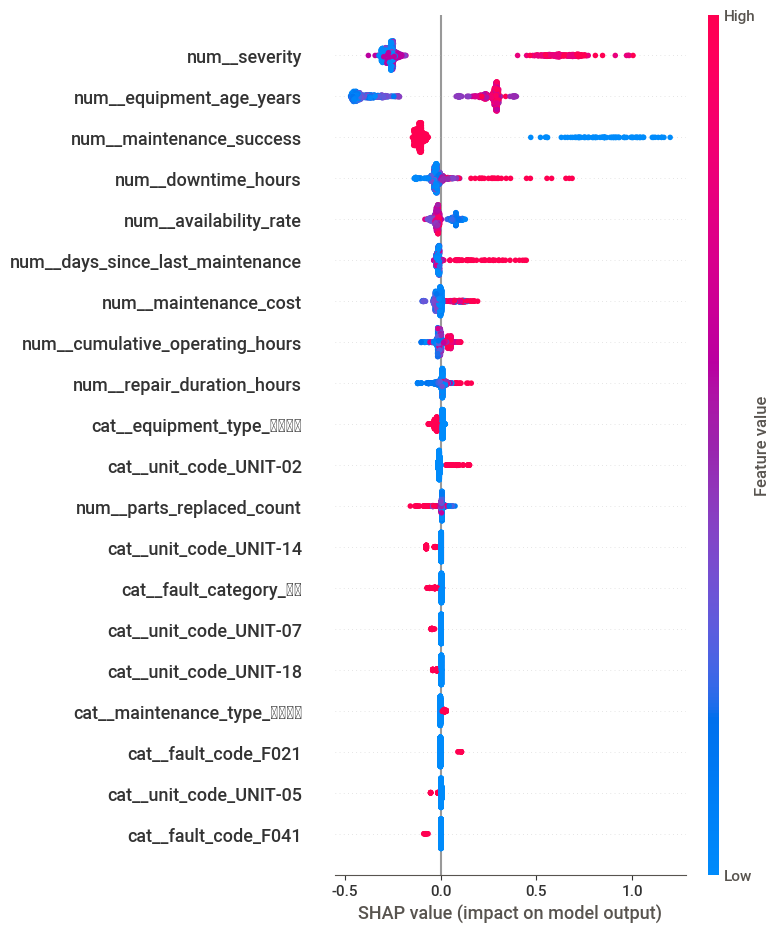

In [78]:
import shap

# 전처리된 피처 행렬 + 피처명 추출
X_test_pre = best_model['pre'].transform(X_test)
feat_names = best_model['pre'].get_feature_names_out()
if hasattr(X_test_pre, 'toarray'):
    X_test_pre = X_test_pre.toarray()
X_test_pre_df = pd.DataFrame(X_test_pre, columns=feat_names)

explainer = shap.TreeExplainer(best_model['model'])
shap_values = explainer(X_test_pre_df)

# 그래프 전에 '평균 |SHAP|' 기준 상위 피처를 표로 출력 → 어떤 변수가 중요한지 수치로 확인
mean_abs = np.abs(shap_values.values).mean(axis=0)
imp = (pd.DataFrame({'feature': feat_names, 'mean_abs_shap': mean_abs})
         .sort_values('mean_abs_shap', ascending=False).head(10).reset_index(drop=True))
print('=== 영향력 상위 10개 피처 (평균 |SHAP| 값) ===')
print(imp.to_string(index=False))

# 전체 피처 중요도 (beeswarm)
shap.summary_plot(shap_values, X_test_pre_df, show=True)

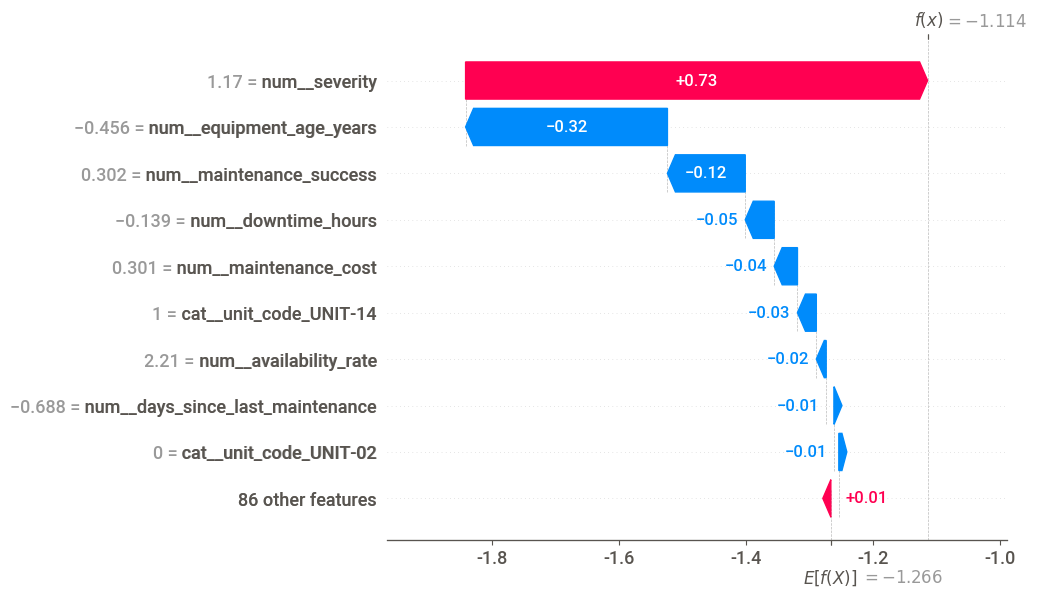

In [79]:
# 단일 샘플 예측 근거 (waterfall)
shap.plots.waterfall(shap_values[0])

---
## 심화 — 예방정비 결측치 처리 전략별 모델 영향 비교

`maintenance_type == '예방정비'` 인 정비건은 **고장이 없으므로** `fault_code`·`fault_category` 가 비어 있고 `severity`=0 이다.
이 결측은 무작위 결측(MCAR)이 아니라 **"예방정비"라는 사실을 그대로 반영하는 구조적·정보성 결측(MNAR)** 이다.
즉 *결측 자체가 신호*이므로, 함부로 채우거나 버리면 정보가 왜곡·소실될 수 있다.

**처리 전략 후보**

| 전략 | 방식 | 장점 | 위험 |
|---|---|---|---|
| `drop_cols` | fault_code/category **컬럼 제거** | 단순 | 고장정보 완전 포기 |
| `drop_rows` | 예방정비 **행 제거** | 결측 원천 제거 | 데이터 40% 손실 + **문제 정의가 바뀜** |
| `na_category` | **'N/A' 명시 범주** (현재 해답지) | 구조적 결측을 그대로 인코딩, 의미 정확 | 거의 없음 |
| `mode_impute` | 최빈 고장코드로 대체 | 결측 제거 | **"예방정비인데 고장났다"는 거짓 정보 주입** |
| `na_plus_flag` | 'N/A' 범주 + `has_fault_info` 지시자 | 결측 여부를 명시 피처화 | maintenance_type와 중복 가능 |

먼저 결측이 **정보성**인지(타깃과 연관) 확인한 뒤, 동일 모델·동일 GroupKFold로 전략별 성능을 비교한다.

In [80]:
# 1) 결측이 '구조적·정보성'인지 확인
is_prev = df['maintenance_type'].eq('예방정비')
print('예방정비 건수 :', int(is_prev.sum()), f'({is_prev.mean()*100:.1f}%)')
print('fault_code 결측 ⟺ 예방정비 일치? :', bool((df['fault_code'].isnull() == is_prev).all()))

print('\n● 정비유형별 severity 평균 (예방정비=0 → 사실상 결측 지시자):')
print(df.groupby('maintenance_type')['severity'].mean().to_string())

print('\n● fault_code 결측 여부별 30일내 재고장률 (정보성 결측 점검):')
rate = df.assign(is_missing=df['fault_code'].isnull()).groupby('is_missing')[TARGET].mean()
print(rate.to_string())
print(f'\n→ 결측(예방정비) 재고장률 {rate[True]:.3f} vs 비결측 {rate[False]:.3f} : '
      f'결측 자체가 타깃과 연관 = 정보성 결측(MNAR). 단순 삭제/최빈대체는 신호 왜곡 위험.')

예방정비 건수 : 2008 (40.2%)
fault_code 결측 ⟺ 예방정비 일치? : True

● 정비유형별 severity 평균 (예방정비=0 → 사실상 결측 지시자):
maintenance_type
긴급정비    4.208169
사후정비    2.746529
예방정비    0.000000

● fault_code 결측 여부별 30일내 재고장률 (정보성 결측 점검):
is_missing
False    0.230949
True     0.141434

→ 결측(예방정비) 재고장률 0.141 vs 비결측 0.231 : 결측 자체가 타깃과 연관 = 정보성 결측(MNAR). 단순 삭제/최빈대체는 신호 왜곡 위험.


### 전략별 비교 — 동일 모델(XGBoost) · 동일 그룹 분할(GroupShuffleSplit + GroupKFold)

5가지 결측 처리 전략을 **같은 조건**에서 학습/평가해 PR-AUC·ROC-AUC를 비교한다.
주의: `drop_rows`는 행 수(=평가 모집단)가 달라지므로 다른 전략과 점수를 **직접 비교할 수 없다**(아래 인사이트 참고).

          전략   행수  피처수(OHE)  CV_PR-AUC  Test_PR-AUC  Test_ROC-AUC
   drop_cols 5000        38     0.3510       0.3822        0.6871
   drop_rows 2992        92     0.4084       0.4442        0.7247
 na_category 5000        95     0.3520       0.3849        0.6900
 mode_impute 5000        93     0.3534       0.3852        0.6887
na_plus_flag 5000        96     0.3520       0.3849        0.6900


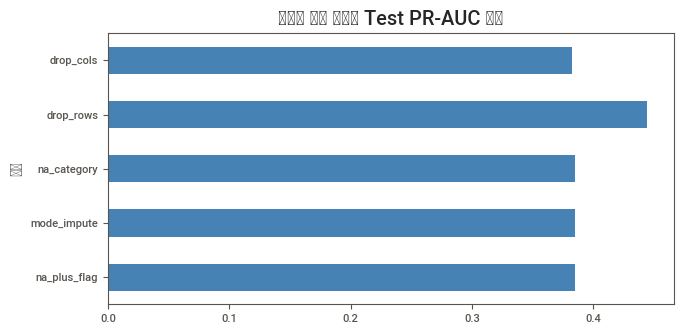

,전략,행수,피처수(OHE),CV_PR-AUC,Test_PR-AUC,Test_ROC-AUC
0,drop_cols,5000,38,0.3510,0.3822,0.6871
1,drop_rows,2992,92,0.4084,0.4442,0.7247
2,na_category,5000,95,0.3520,0.3849,0.6900
3,mode_impute,5000,93,0.3534,0.3852,0.6887
4,na_plus_flag,5000,96,0.3520,0.3849,0.6900


In [81]:
# 2) 전략별 결측 처리 → 동일 파이프라인으로 성능 비교
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

def build_X(d0, strat):
    """전략별로 예방정비 결측(fault_code/category)을 다르게 처리해 X, y, groups 생성."""
    d = d0.copy()
    # 공통: 최초 정비건 결측은 0 + 플래그 (전략과 무관)
    d['is_first_maintenance'] = d['days_since_last_maintenance'].isnull().astype(int)
    d['days_since_last_maintenance'] = d['days_since_last_maintenance'].fillna(0)
    if strat == 'drop_cols':            # ① 미처리: 결측 컬럼 자체 제거
        d = d.drop(columns=['fault_code', 'fault_category'])
    elif strat == 'drop_rows':          # ② 예방정비 행 제거 (문제 정의가 달라짐 주의)
        d = d[d['fault_code'].notnull()].copy()
    elif strat == 'na_category':        # ③ 'N/A' 명시 범주 (현재 해답지 방식)
        d['fault_code'] = d['fault_code'].fillna('N/A')
        d['fault_category'] = d['fault_category'].fillna('N/A')
    elif strat == 'mode_impute':        # ④ 최빈값 대체 (거짓 고장정보 주입 — 비교용)
        d['fault_code'] = d['fault_code'].fillna(d['fault_code'].mode().iloc[0])
        d['fault_category'] = d['fault_category'].fillna(d['fault_category'].mode().iloc[0])
    elif strat == 'na_plus_flag':       # ⑤ 'N/A' 범주 + 결측 지시자 피처
        d['has_fault_info'] = d['fault_code'].notnull().astype(int)
        d['fault_code'] = d['fault_code'].fillna('N/A')
        d['fault_category'] = d['fault_category'].fillna('N/A')
    g = d['equipment_id']
    X = d.drop(columns=[c for c in ['equipment_id', 'maintenance_date', TARGET] if c in d])
    return X, d[TARGET], g

def evaluate_strategy(strat):
    X, y, g = build_X(df, strat)
    num = X.select_dtypes('number').columns.tolist()
    cat = X.select_dtypes('object').columns.tolist()
    pre = ColumnTransformer([('num', StandardScaler(), num),
                             ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)])
    spw = (y == 0).sum() / (y == 1).sum()
    model = Pipeline([('pre', pre),
                      ('model', XGBClassifier(random_state=42, eval_metric='logloss',
                                              scale_pos_weight=spw, max_depth=3,
                                              n_estimators=300, learning_rate=0.03))])
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    tr, te = next(gss.split(X, y, groups=g))
    Xtr, Xte, ytr, yte, gtr = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], g.iloc[tr]
    cv = cross_validate(model, Xtr, ytr, cv=GroupKFold(5), groups=gtr,
                        scoring=['average_precision'])
    model.fit(Xtr, ytr)
    proba = model.predict_proba(Xte)[:, 1]
    return {'전략': strat, '행수': len(X),
            '피처수(OHE)': len(model['pre'].get_feature_names_out()),
            'CV_PR-AUC': round(cv['test_average_precision'].mean(), 4),
            'Test_PR-AUC': round(average_precision_score(yte, proba), 4),
            'Test_ROC-AUC': round(roc_auc_score(yte, proba), 4)}

STRATS = ['drop_cols', 'drop_rows', 'na_category', 'mode_impute', 'na_plus_flag']
comp_df = pd.DataFrame([evaluate_strategy(s) for s in STRATS])
print(comp_df.to_string(index=False))

ax = comp_df.set_index('전략')['Test_PR-AUC'].plot(
    kind='barh', figsize=(7, 3.5), color='steelblue',
    title='결측치 처리 전략별 Test PR-AUC 비교')
ax.invert_yaxis(); plt.tight_layout(); plt.show()
comp_df

#### 📈 인사이트 — 결측치 처리 전략 비교 결과

| 전략 | 행수 | Test PR-AUC | Test ROC-AUC | 평가 |
|---|---|---|---|---|
| `drop_cols` | 5,000 | ~0.382 | ~0.687 | 컬럼 제거해도 손실 거의 없음 |
| **`drop_rows`** | 2,992 | **~0.444** | **~0.725** | ⚠ 수치는 최고지만 **함정** |
| `na_category`(현재) | 5,000 | ~0.385 | ~0.690 | ✅ 권장 |
| `mode_impute` | 5,000 | ~0.385 | ~0.689 | 점수는 같으나 의미 오류 |
| `na_plus_flag` | 5,000 | ~0.385 | ~0.690 | 지시자 효과 미미 |

**핵심 결론**
1. **행을 모두 유지하는 4개 전략의 성능이 사실상 동일**하다. 결측의 신호(예방정비=고장 없음)가 **이미 `maintenance_type='예방정비'`·`severity=0`에 담겨 있어서** `fault_code` 인코딩 방식이 추가 정보를 거의 주지 못하기 때문. → `na_plus_flag`의 지시자도, `mode_impute`의 대체값도 **중복**이라 효과가 없다.
2. **`drop_rows`(예방정비 제거)가 가장 높은 PR-AUC를 보이지만 "더 좋은 처리"가 아니다.** 분류가 쉬운 저위험 그룹(예방정비, 재고장률 0.14)을 통째로 빼고 **다른(더 어려운) 모집단**에서 평가한 것뿐이다. 데이터 40%(2,008건)를 버렸고 예측 대상 자체가 바뀌었다. → **수치만 보고 전략을 고르면 안 된다**는 대표적 함정.
3. **`mode_impute`는 "예방정비인데 특정 고장이 났다"는 거짓 정보를 주입**한다. 여기서는 신호가 다른 변수에 있어 점수에 안 드러났을 뿐, 의미상 틀린 처리이며 다른 데이터에선 왜곡을 일으킬 수 있다. → **지표가 같다고 옳은 처리는 아니다.**

**권장**: 구조적·정보성 결측은 **`na_category`(전용 'N/A' 범주)로 명시 인코딩**한다. 의미가 정확하고 트리/선형 모델 모두에서 안전하며 행 손실이 없다. (단순화를 원하면 `drop_cols`도 무방 — 이 데이터에선 차이가 미미.)

### ✏️ 직접 해보기
위 모델 비교 결과를 plotly 막대 차트로 시각화하고, 상위 2개 모델의 ROC 커브를 한 그래프에 겹쳐 그려보세요.

---
# 실습 4 — 예측 앱 제작 및 자동화

**학습 목표**: joblib 저장/로드 + Streamlit 실시간 예측 + 예측 결과 CSV 자동 기록.

## STEP 1 — 모델 저장 및 로드

In [82]:
import joblib
from pathlib import Path

Path('artifacts').mkdir(exist_ok=True)
joblib.dump(best_model, 'artifacts/model.pkl')
# 입력 스키마(컬럼/타입/기본값/임계값)도 저장 → 예측 앱 폼 자동 생성 + 합리적 기본값
joblib.dump({'num_cols': num_cols, 'cat_cols': cat_cols,
             'cat_options': {c: sorted(X_train[c].unique().tolist()) for c in cat_cols},
             'num_defaults': X_train[num_cols].median().to_dict(),   # 수치형 기본값=중앙값
             'decision_threshold': best_thr},                        # 튜닝된 임계값
            'artifacts/schema.pkl')
print('저장 완료 → artifacts/model.pkl, artifacts/schema.pkl')

# 로드 확인
loaded = joblib.load('artifacts/model.pkl')
print('로드 확인 — 첫 샘플 예측 :', int(loaded.predict(X_test.iloc[[0]])[0]))

저장 완료 → artifacts/model.pkl, artifacts/schema.pkl
로드 확인 — 첫 샘플 예측 : 0


## STEP 2~3 — 예측 앱 제작 + 결과 자동 저장 (predict_app.py)
저장된 스키마를 읽어 피처 입력 폼을 자동 생성하고, 예측 시 `predictions.csv`에 자동 누적 저장합니다.

In [83]:
%%writefile predict_app.py
import os, datetime
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(page_title='장비 재고장 예측', layout='centered')
st.title('🔮 장비 30일내 재고장 예측 앱')

model = joblib.load('artifacts/model.pkl')
schema = joblib.load('artifacts/schema.pkl')
THR = schema.get('decision_threshold', 0.5)   # 학습 때 정한 임계값(기본 0.5 아님)

st.subheader('장비/정비 정보 입력')
inp = {}
# 범주형 → selectbox
for c in schema['cat_cols']:
    inp[c] = st.selectbox(c, schema['cat_options'][c])
# 수치형 → number_input (기본값=학습 데이터 중앙값 → 부분 입력 시에도 합리적)
for c in schema['num_cols']:
    inp[c] = st.number_input(c, value=float(schema['num_defaults'][c]))

if st.button('예측하기'):
    input_df = pd.DataFrame([inp])
    proba = float(model.predict_proba(input_df)[0, 1])
    pred = int(proba >= THR)                   # 튜닝된 임계값으로 판정
    if pred == 1:
        st.error(f'⚠ 30일 내 재고장 위험 — 확률 {proba*100:.1f}% (임계값 {THR:.2f})')
    else:
        st.success(f'✅ 재고장 위험 낮음 — 재고장 확률 {proba*100:.1f}% (임계값 {THR:.2f})')

    # 결과를 CSV에 자동 누적 저장
    log = input_df.copy()
    log['prediction'] = pred
    log['proba'] = round(proba, 4)
    log['timestamp'] = datetime.datetime.now()
    path = 'predictions.csv'
    log.to_csv(path, mode='a', header=not os.path.exists(path), index=False)
    st.info('결과가 predictions.csv에 저장되었습니다.')

Overwriting predict_app.py


### 앱 실행
```bash
streamlit run predict_app.py
```

### ✏️ 직접 해보기
저장된 `predictions.csv`를 읽어 예측 히스토리를 테이블과 시계열 차트로 보여주는 탭을 추가해보세요.

---
# 선택 Lab — 시각화 고도화 

## Lab A — seaborn 고급 시각화

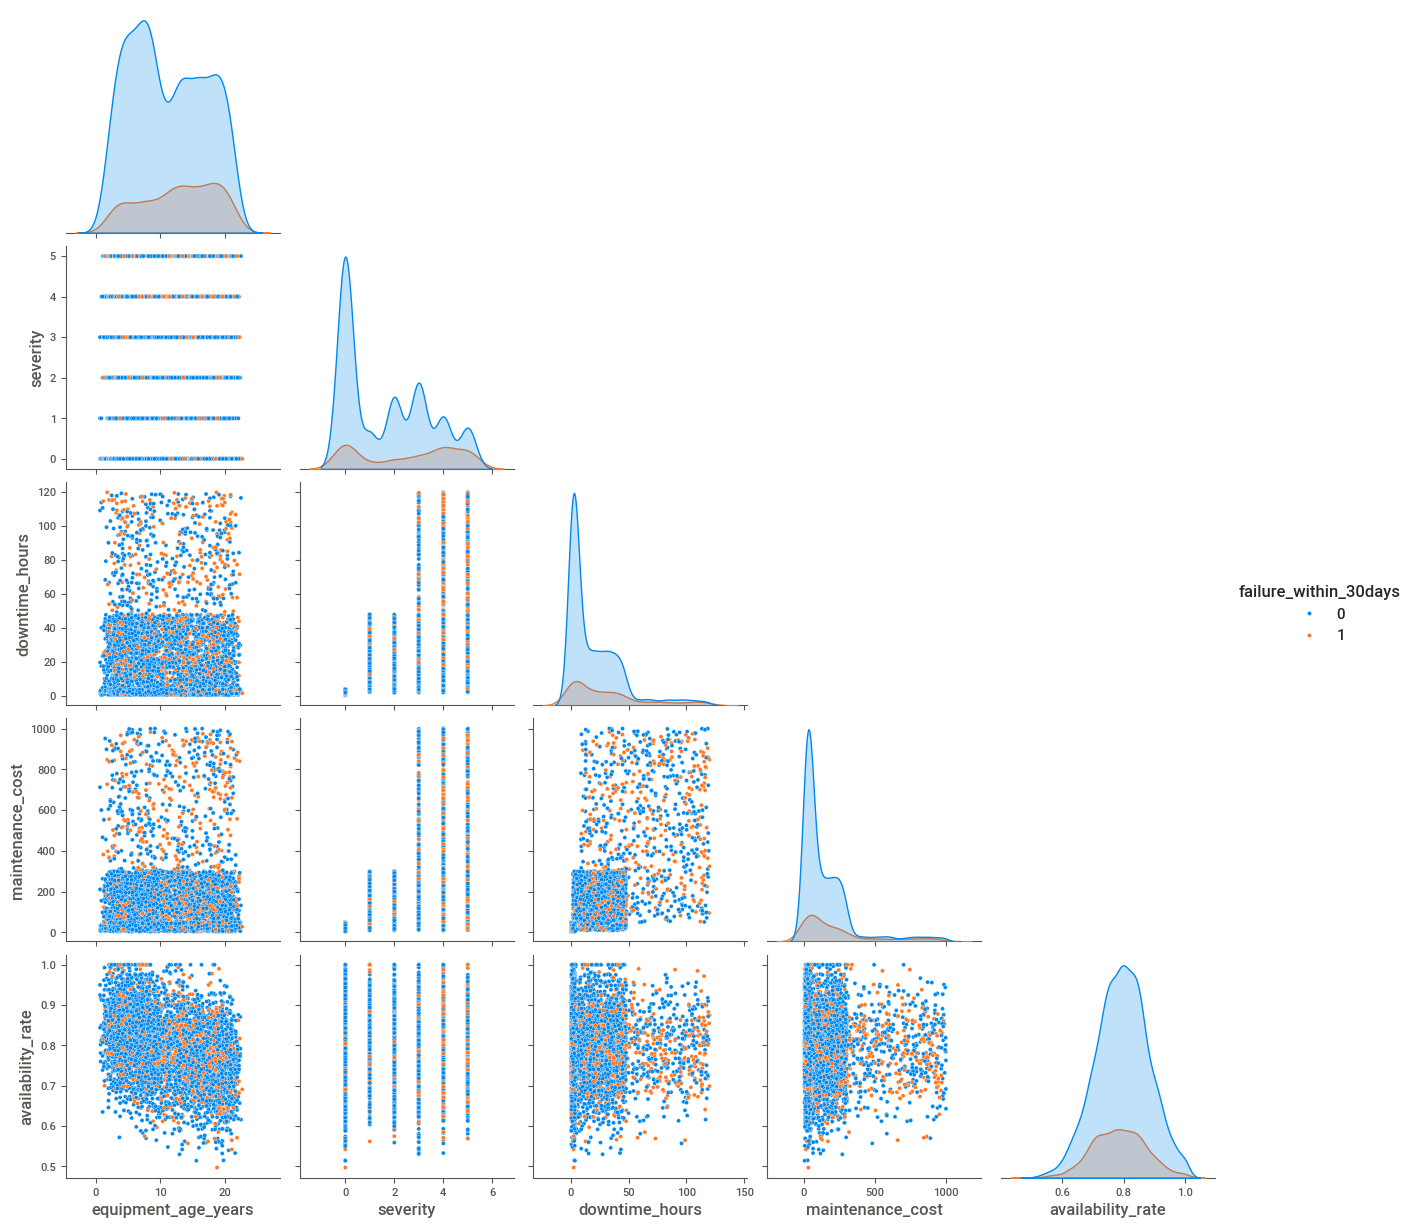

In [84]:
# 페어플롯: 핵심 수치형 조합 (전체 컬럼은 무거우므로 일부만)
key_num = ['equipment_age_years', 'severity', 'downtime_hours',
           'maintenance_cost', 'availability_rate']
sns.pairplot(df[key_num + [TARGET]], hue=TARGET, corner=True)
plt.show()

## Lab B — plotly 인터랙티브 시각화

In [85]:
import plotly.express as px

# 3D 산점도: 경과연수 × 누적가동시간 × 정비비용
fig = px.scatter_3d(df, x='equipment_age_years', y='cumulative_operating_hours',
                    z='maintenance_cost', color=df[TARGET].astype(str),
                    opacity=0.6, title='장비 노후도 vs 가동시간 vs 비용')
fig.show()

In [86]:
# 월별 재고장률 추이 애니메이션 소재 — 정비유형별 월별 건수
tmp = df.copy()
tmp['month'] = tmp['maintenance_date'].dt.to_period('M').astype(str)
g = tmp.groupby(['month', 'maintenance_type']).size().reset_index(name='건수')
fig2 = px.bar(g, x='maintenance_type', y='건수', color='maintenance_type',
              animation_frame='month', title='월별 정비유형 건수 추이')
fig2.show()

---
# 고급 Lab — MLOps 자동화 파이프라인

## Lab A — MLflow 실험 추적
모델 학습 실험의 파라미터·메트릭·아티팩트를 자동 기록/비교하는 MLOps 플랫폼.

In [87]:
import mlflow, mlflow.sklearn
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score

mlflow.set_experiment('equipment_failure_prediction')

# 주의: STEP 1의 그룹(장비) 분할로 만든 X_train/X_test를 그대로 사용 → 누수 없는 비교.
for name, model in models.items():
    with mlflow.start_run(run_name=name):
        pipe = Pipeline([('pre', preprocessor), ('model', model)])
        pipe.fit(X_train, y_train)
        proba = pipe.predict_proba(X_test)[:, 1]
        pred = (proba >= 0.5).astype(int)
        mlflow.log_param('model', name)
        # 불균형 → PR-AUC를 주지표로 함께 기록
        mlflow.log_metric('pr_auc', average_precision_score(y_test, proba))
        mlflow.log_metric('roc_auc', roc_auc_score(y_test, proba))
        mlflow.log_metric('f1_pos', f1_score(y_test, pred, pos_label=1))
        mlflow.sklearn.log_model(pipe, 'model')
print('기록 완료 — 터미널에서  mlflow ui  실행 후 http://localhost:5000 확인')

2026/06/24 11:24:34 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/06/24 11:24:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/06/24 11:24:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/06/24 11:24:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_p

기록 완료 — 터미널에서  mlflow ui  실행 후 http://localhost:5000 확인


## Lab B — Prefect 파이프라인 자동화
Python 함수를 task/flow로 감싸 워크플로우를 정의하고 스케줄·재시도·모니터링을 자동화합니다.
아래 셀로 `ml_pipeline.py`를 생성한 뒤 `python ml_pipeline.py`로 실행하세요.

In [88]:
%%writefile ml_pipeline.py
import pandas as pd
import joblib
from prefect import flow, task
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

DATA_PATH = 'data/dataset1_equipment_maintenance.xlsx'
TARGET = 'failure_within_30days'

@task
def load_data(path):
    df = pd.read_excel(path, sheet_name='데이터')
    df['maintenance_date'] = pd.to_datetime(df['maintenance_date'])
    return df

@task
def preprocess(df):
    df = df.copy()
    df['fault_code'] = df['fault_code'].fillna('N/A')
    df['fault_category'] = df['fault_category'].fillna('N/A')
    df['days_since_last_maintenance'] = df['days_since_last_maintenance'].fillna(0)
    # maintenance_date 만 제거. equipment_id 는 그룹 분할용으로 유지 후 분할 직전 제거.
    return df.drop(columns=['maintenance_date'])

@task
def train_model(df):
    groups = df['equipment_id']
    X = df.drop(columns=[TARGET, 'equipment_id']); y = df[TARGET]
    # 그룹(장비) 기준 분할 — 같은 장비가 train/test에 동시에 들어가는 누수 방지
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    tr, te = next(gss.split(X, y, groups=groups))
    X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    # 불균형 보정
    spw = (y_tr == 0).sum() / (y_tr == 1).sum()
    num = X.select_dtypes('number').columns.tolist()
    cat = X.select_dtypes('object').columns.tolist()
    pre = ColumnTransformer([('num', StandardScaler(), num),
                             ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)])
    pipe = Pipeline([('pre', pre),
                     ('model', XGBClassifier(random_state=42, eval_metric='logloss',
                                             scale_pos_weight=spw))])
    pipe.fit(X_tr, y_tr)
    proba = pipe.predict_proba(X_te)[:, 1]
    auc = roc_auc_score(y_te, proba)
    ap = average_precision_score(y_te, proba)
    print(f'Test ROC-AUC: {auc:.4f} | PR-AUC: {ap:.4f}')
    joblib.dump(pipe, 'artifacts/model.pkl')
    return ap

@flow(name='equipment-failure-pipeline')
def ml_pipeline(data_path=DATA_PATH):
    df = load_data(data_path)
    df = preprocess(df)
    return train_model(df)

if __name__ == '__main__':
    ml_pipeline()

Overwriting ml_pipeline.py


### 🔴 고급 Lab 챌린지
MLflow로 3가지 이상 모델(RandomForest, XGBoost, LightGBM)을 실험 추적하고, 가장 성능 좋은 모델을
자동 선택해 Streamlit 앱에 배포하는 전체 파이프라인을 구성해보세요.

---
# 부록 — 자주 쓰는 패턴 & 마무리

### 데이터 전처리 치트시트

In [89]:
# 범주형 → 원-핫
# df = pd.get_dummies(df, columns=['equipment_type'], drop_first=True)

# Label Encoding
# from sklearn.preprocessing import LabelEncoder
# df['equipment_type_le'] = LabelEncoder().fit_transform(df['equipment_type'])

# 날짜 피처 추출
# df['year'] = df['maintenance_date'].dt.year
# df['month'] = df['maintenance_date'].dt.month
# df['dayofweek'] = df['maintenance_date'].dt.dayofweek

### Streamlit 배포 체크리스트
- [ ] `requirements.txt` 작성 완료
- [ ] secrets/API 키는 `st.secrets` 또는 `.env` 사용 (`.streamlit/secrets.toml`은 git 제외)
- [ ] Streamlit Cloud 또는 Docker로 배포
- [ ] 데이터 캐싱 `@st.cache_data` 적용 확인

### 💡 학습 마무리 TIP
오늘 만든 코드를 GitHub에 올리고 README.md에 무엇을 배웠는지 기록해보세요. 포트폴리오의 시작이 됩니다.
작성한 코드는 반드시 직접 이해하고 설명할 수 있어야 합니다.